# Gradient Descent step by step

In [167]:
from sklearn.datasets import make_regression
import numpy as np


In [168]:

X,y = make_regression(n_samples=4, n_features=1, n_informative=1, n_targets=1,noise=80,random_state=13)

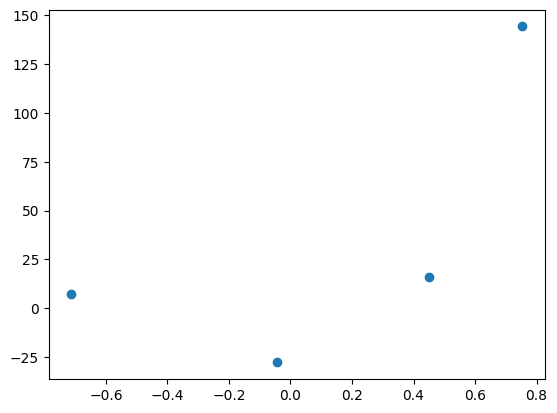

In [169]:
import matplotlib.pyplot as plt
plt.scatter(X,y)

In [170]:

# Lets apply OLS
from sklearn.linear_model import LinearRegression

In [171]:
reg=LinearRegression()

In [172]:
reg.fit(X,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [173]:
reg.coef_  # m  slope

array([78.35063668])

In [174]:
reg.intercept_  # b intercept

np.float64(26.15963284313262)

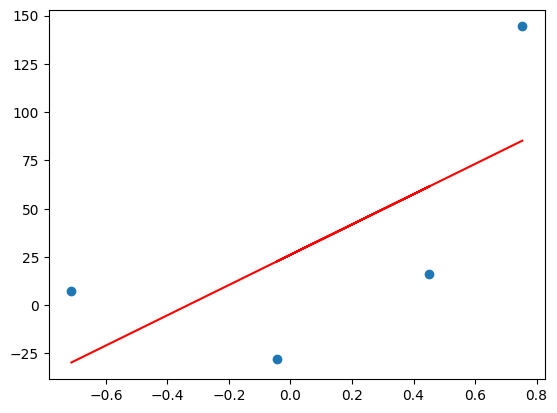

In [175]:
plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red')

In [176]:
# Lets apply Gradient Descent assuming slope is constant m = 78.35
# and let's assume the starting value for intercept b = 0
#m = 78.35 → slope / coefficient
# b = 100 → intercept
# X → input features
# y_pred → predicted output
# y=mx+b
y_pred = ((78.35 * X) + 100).reshape(4)

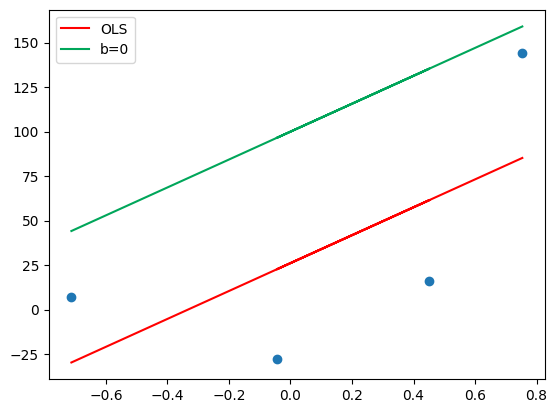

In [177]:
plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red',label='OLS')
plt.plot(X,y_pred,color='#00a65a',label='b=0')
plt.legend()
plt.show()

In [178]:
m=78.35
b=100

loss_slope=-2 * np.sum(y-m*X.ravel()-b)
loss_slope



np.float64(590.7223659179078)

In [179]:
# lets take learning rate 0.1
lr=0.1

step_size=loss_slope*lr
step_size

np.float64(59.072236591790784)

In [180]:
# calculate the new intercept
b= b-step_size
b

np.float64(40.927763408209216)

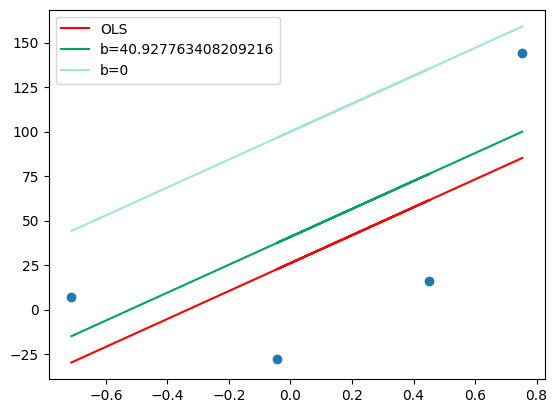

In [181]:
y_pred1=((78.35*X)+b).reshape(4)

plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red',label='OLS')
plt.plot(X,y_pred1,color='#00a65a',label='b={}'.format(b))
plt.plot(X,y_pred,color="#A3E4D7",label='b=0')
plt.legend()
plt.show()

In [182]:
# iteration 2
loss_slope=-2 * np.sum(y-m*X.ravel()-b)
loss_slope

np.float64(118.14447318358157)

In [183]:
step_size=loss_slope*lr
step_size

np.float64(11.814447318358157)

In [184]:
b=b-step_size
b

np.float64(29.11331608985106)

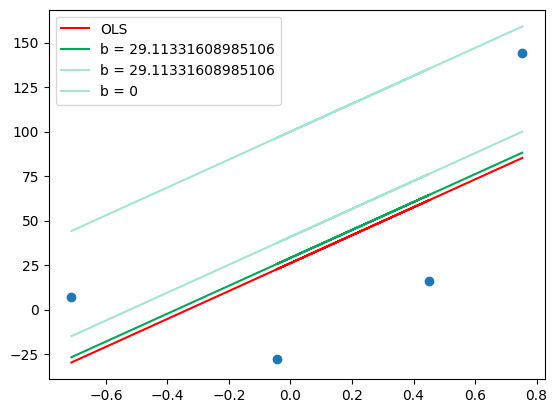

In [185]:
y_pred2 = ((78.35 * X) + b).reshape(4)

plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red',label='OLS')
plt.plot(X,y_pred2,color='#00a65a',label='b = {}'.format(b))
plt.plot(X,y_pred1,color='#A3E4D7',label='b = {}'.format(b))
plt.plot(X,y_pred,color='#A3E4D7',label='b = 0')
plt.legend()
plt.show()


In [186]:


# Iteration 3
loss_slope = -2 * np.sum(y - m*X.ravel() - b)
loss_slope

np.float64(23.62889463671634)

In [187]:


step_size = loss_slope*lr
step_size

np.float64(2.362889463671634)

In [188]:

b = b - step_size
b


np.float64(26.750426626179426)

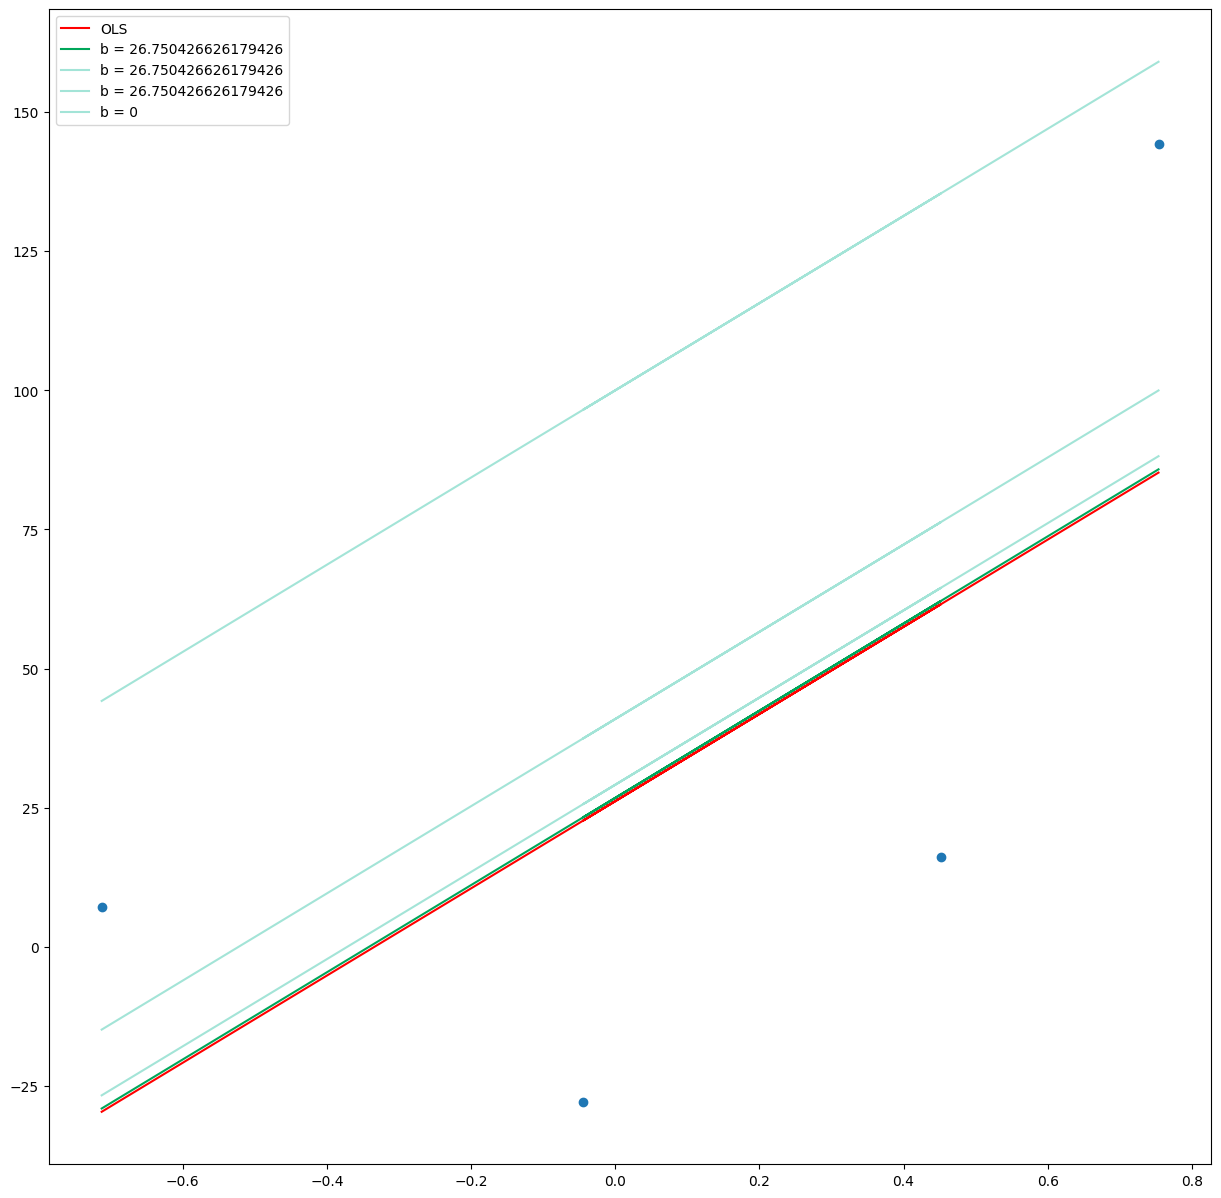

In [189]:


y_pred3 = ((78.35 * X) + b).reshape(4)

plt.figure(figsize=(15,15))
plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red',label='OLS')
plt.plot(X,y_pred3,color='#00a65a',label='b = {}'.format(b))
plt.plot(X,y_pred2,color='#A3E4D7',label='b = {}'.format(b))
plt.plot(X,y_pred1,color='#A3E4D7',label='b = {}'.format(b))
plt.plot(X,y_pred,color='#A3E4D7',label='b = 0')
plt.legend()
plt.show()

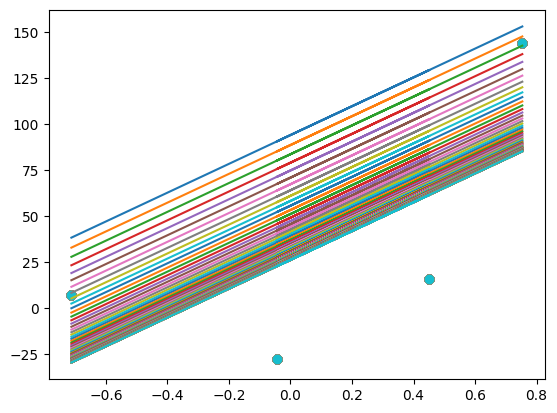

In [190]:
b =100
m=78.35
lr=0.01
epochs=100
for i in range(epochs):
    loss_slope=-2 * np.sum(y - m*X.ravel() - b)
    b=b-(lr*loss_slope)

    y_pred=m*X+b
    plt.plot(X,y_pred)
    plt.scatter(X,y)

# create class GD regressor

In [191]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np

In [192]:
X,y= make_regression(n_samples=100,n_features=1,n_informative=1,n_targets=1,noise=20,random_state=13)

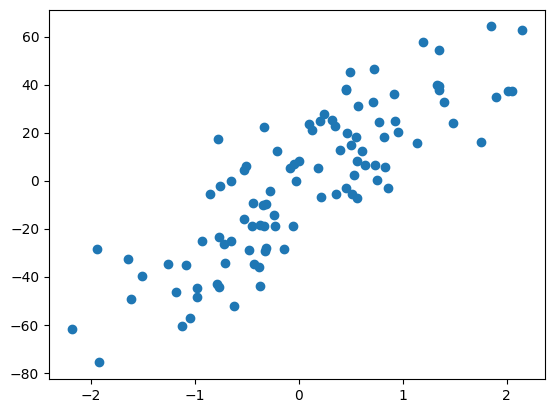

In [193]:
plt.scatter(X,y)

In [194]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=2)

In [195]:
from sklearn.linear_model import LinearRegression

In [196]:
lr=LinearRegression()

In [197]:
lr.fit(X_train,y_train)
print(lr.coef_)
print(lr.intercept_)

[28.12597332]
-2.2710144261783825


In [198]:
m=28.12


In [206]:
class GDregressor:
    def __init__(self,learning_rate,epochs):
        self.m=28.12
        self.b=-120
        self.lr=learning_rate
        self.epochs=epochs


    def fit(self,X,y):
        # calculate the b using gardient desent
        for i in range(self.epochs):
            loss_slope=-2 * np.sum(y-self.m*X.ravel()-self.b)
            self.b=self.b-(self.lr*loss_slope)
            print(loss_slope,  self.b)

        print(self.b)
            




In [207]:
gd=GDregressor(0.001,100)


In [208]:
gd.fit(X,y)

-23537.64116001603 -96.46235883998396
-18830.11292801282 -77.63224591197114
-15064.090342410256 -62.568155569560886
-12051.272273928204 -50.51688329563268
-9641.017819142568 -40.87586547649011
-7712.814255314051 -33.16305122117606
-6170.251404251242 -26.99279981692482
-4936.201123400993 -22.056598693523824
-3948.9608987207935 -18.107637794803033
-3159.168718976635 -14.948469075826399
-2527.3349751813084 -12.42113410064509
-2021.8679801450467 -10.399266120500045
-1617.4943841160375 -8.781771736384007
-1293.99550729283 -7.4877762290911765
-1035.1964058342637 -6.4525798232569125
-828.157124667411 -5.624422698589502
-662.5256997339287 -4.961896998855573
-530.0205597871429 -4.4318764390684295
-424.01644782971437 -4.007859991238715
-339.2131582637714 -3.6686468329749435
-271.37052661101717 -3.3972763063639264
-217.09642128881381 -3.1801798850751126
-173.677137031051 -3.0065027480440616
-138.94170962484083 -2.867561038419221
-111.15336769987276 -2.7564076707193483
-88.92269415989811 -2.667484

In [ ]:

# class GDRegressor:
    
#     def __init__(self,learning_rate,epochs):
#         self.m = 100
#         self.b = -120
#         self.lr = learning_rate
#         self.epochs = epochs
        
#     def fit(self,X,y):
#         # calcualte the b using GD
#         for i in range(self.epochs):
#             loss_slope_b = -2 * np.sum(y - self.m*X.ravel() - self.b)
#             loss_slope_m = -2 * np.sum((y - self.m*X.ravel() - self.b)*X.ravel())
            
#             self.b = self.b - (self.lr * loss_slope_b)
#             self.m = self.m - (self.lr * loss_slope_m)
#         print(self.m,self.b)
        
#     def predict(self,X):
#         return self.m * X + self.b